<a href="https://colab.research.google.com/github/esnakaridharanioffical-lgtm/ML_LAB_2026-27/blob/main/Mini_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Importing the new Dataset**

In [13]:
import pandas as pd

df = pd.read_csv('/content/Iris.csv')

print(df.head())
print("Dataset shape:", df.shape)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Dataset shape: (150, 6)


**Import the required libraries**

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

**Prepare the dataset**

In [15]:
df = df.drop(columns=['Id'], errors='ignore')

X = df.drop('Species', axis=1)
y = df['Species']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Data preparation completed!")

Training samples: 120
Testing samples: 30
Data preparation completed!


**Algorithm 1 — Decision Tree**

In [16]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions) * 100, "%")

print(classification_report(y_test, dt_predictions))

Decision Tree Accuracy: 93.33333333333333 %
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



**Algorithm 2 — K-Nearest Neighbors**

In [17]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_predictions) * 100, "%")

print(classification_report(y_test, knn_predictions))

KNN Accuracy: 93.33333333333333 %
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



**Algorithm 3 — Logistic Regression**

In [18]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions) * 100, "%")

print(classification_report(y_test, lr_predictions))

Logistic Regression Accuracy: 93.33333333333333 %
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



**Algorithm 4 — Support Vector Machine**

In [19]:
from sklearn.svm import SVC

svm_model = SVC(kernel='linear')

svm_model.fit(X_train_scaled, y_train)

svm_predictions = svm_model.predict(X_test_scaled)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_predictions) * 100, "%")

print(classification_report(y_test, svm_predictions))

SVM Accuracy: 100.0 %
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



**Compare all four algorithms**

          Algorithm  Accuracy (%)
      Decision Tree     93.333333
                KNN     93.333333
Logistic Regression     93.333333
                SVM    100.000000


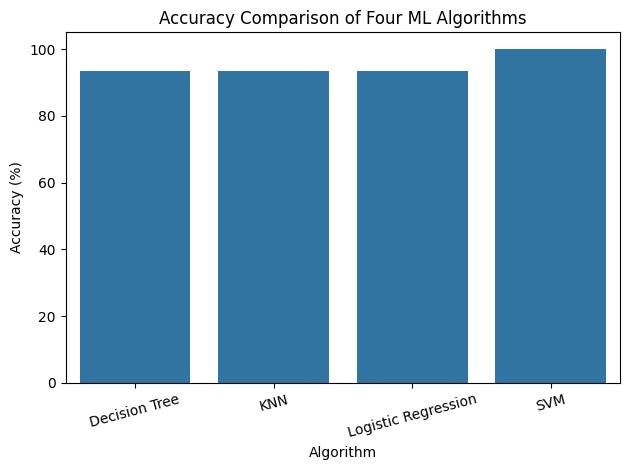

In [20]:
results = pd.DataFrame({
    'Algorithm': [
        'Decision Tree',
        'KNN',
        'Logistic Regression',
        'SVM'
    ],
    'Accuracy (%)': [
        accuracy_score(y_test, dt_predictions) * 100,
        accuracy_score(y_test, knn_predictions) * 100,
        accuracy_score(y_test, lr_predictions) * 100,
        accuracy_score(y_test, svm_predictions) * 100
    ]
})

print(results.to_string(index=False))

sns.barplot(data=results, x='Algorithm', y='Accuracy (%)')
plt.title('Accuracy Comparison of Four ML Algorithms')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()